# TopoPyScale in the Pyrenees (2/2): what the downscaling does


**Workshop demo**: ERA5 (2019–2020) downscaled with [TopoPyScale](https://github.com/ArcticSnow/TopoPyScale)
across the whole Pyrenees, from the Ebro basin (Huesca) to the Béarn piedmont (Pau). Along a ~30 km wide transect
that contains two ERA5 grid columns, we look at:

1. the **long-distance N–S gradient** (Atlantic-influenced north vs Mediterranean/continental south),
2. the **elevation gradient** that ERA5 cannot resolve,
3. the **aspect / terrain gradient of shortwave radiation**,
4. a **validation against the Izas AWS** (2113 m, Spanish Pyrenees), and
5. a **snow simulation** (FSM) driven by the downscaled forcing, compared with the station snow depth.

> **Run [`1_downscaling.ipynb`](1_downscaling.ipynb) first, with the same `MODE` and `ERA5_TIMESTEP = "6h"`.** It runs TopoPyScale and writes
> the outputs that this notebook only loads. The summary of the results and the compute times are at the end of
> notebook 1.

> **Data note.** The ERA5 files provided for the workshop are **6-hourly** (00, 06, 12, 18 UTC). Radiation and
> precipitation are the 1-hour accumulations ending at those times. We downscale at this native 6-hourly step,
> so SW values are *1-hour means at 4 times of the day*, not daily means.

## 1. Setup

Same switches as in notebook 1: `MODE` selects the transect run analysed here (`"light"`: 300 clusters, `"full"`:
3000 clusters), `CPU_CORES` is at most 20 (shared machine). This notebook analyses the 6-hourly 2019–2020 run;
the hourly run of notebook 1 (`ERA5_TIMESTEP = "1h"`) covers only November 2019 – April 2020.

In [1]:
import os

######################################################################################################################
# Switches
MODE = "full"                          # "light": 300 clusters (laptops); "full": 300 and 3000 clusters
CPU_CORES = min(20, os.cpu_count())    # shared machine: at most 20 cores

######################################################################################################################
# Imports. TopoPyScale runs CPU_CORES worker processes: one thread each keeps the total at CPU_CORES cores
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "DASK_NUM_WORKERS"):
    os.environ[v] = "1"
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from functools import partial
from matplotlib.patches import Rectangle
import dask
from threadpoolctl import threadpool_limits

from TopoPyScale import topoclass as tc
import pyr_utils as pu

dask.config.set(num_workers=CPU_CORES)  # the notebook process itself (e.g. reading, clustering) may use CPU_CORES
_limits = threadpool_limits(CPU_CORES)  # threads

######################################################################################################################
# Paths and helpers
RUN_FSM = True
DEM_RES = 30.0                                             # m
CODE_DIR = Path.cwd()
LINKS = pu.load_links()                                    # private workshop links: data_links.yml (not in git)
DATA_ROOT = Path(os.environ.get("TPS_PYR_DATA") or LINKS.get("data_root") or CODE_DIR / "data")
CLIM = DATA_ROOT / "era5_topopyscale"                      # ERA5 re-formatted for TopoPyScale
PROJ_T = DATA_ROOT / f"transect_{MODE}"                    # transect project analysed here
PROJ_I = DATA_ROOT / "izas"                                # points project (Izas)
FSM_EXEC = CODE_DIR / "FSM" / "FSM"
TIMES_FILE = DATA_ROOT / "compute_times.json"              # compute times, shared with notebook 1


def timed(label, cached=False):
    return pu.timed(label, TIMES_FILE, cached)


km = pu.km
for p in (PROJ_T, PROJ_I):
    if not any((p / "outputs" / "downscaled").glob("down_pt_*.nc")):
        raise FileNotFoundError(f"No downscaled outputs in {p}: run 1_downscaling.ipynb first (same MODE)")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print(f"MODE={MODE}  CPU_CORES={CPU_CORES}")

MODE=full  CPU_CORES=20


## 2. Data

* **ERA5** (provided zip): daily `dSURF_*.nc` (z, t2m, d2m, sp, ssrd, strd, tp) and `dPLEV_*.nc`
  (z, t, u, v, q, r on 1000–600 hPa), i.e. the daily files TopoPyScale's `get_era5()` downloads from CDS.
  As in TopoPyScale's workflow we merge them into yearly `SURF_YYYY.nc` / `PLEV_YYYY.nc` (rename
  `valid_time`→`time`, `pressure_level`→`level`, crop around the Pyrenees), check that radiation is indeed a
  1-hour accumulation, and convert them to a **zarr store** (`ERA5.zarr`), which makes the downscaling >10× faster.
  This is done in notebook 1.
* **Izas AWS** (IPE-CSIC): 10-min data 2019–2021, UTC.
* **DEM**: Copernicus GLO-30 (2 tiles).

In [2]:
paths = pu.download_inputs(DATA_ROOT / "raw", LINKS)       # already there after notebook 1: returns the file paths

  found ERA5_Pyr_2019_2020.zip
  found Izas_Meteo_2019-2021.xlsx
  found Copernicus_DSM_COG_10_N42_00_W001_00_DEM.tif
  found Copernicus_DSM_COG_10_N43_00_W001_00_DEM.tif


## 3. The transect and what ERA5 "sees"

The transect is a UTM rectangle **30 km wide**, centred between the two ERA5 grid columns at 0.561°W and 0.311°W,
from **42.10°N (Huesca)** to **43.35°N (Pau)**. The DEM gets an extra 10 km buffer so that horizon angles and
sky-view factors near the edges see the surrounding mountains; only the transect itself is clustered/downscaled.

  dem_transect_30m.tif: 5294 x 1667 px (8.8 million pixels) at 30 m, elevation 70-3237 m


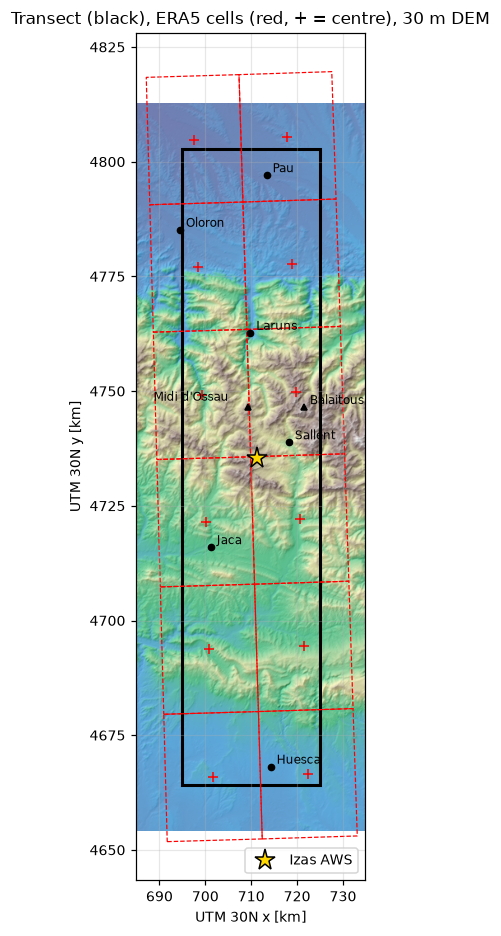

In [3]:
tb, db = pu.transect_bounds(res=DEM_RES, buffer_km=10)
dem = pu.build_dem(paths["dem_tiles"], DATA_ROOT / "dem" / "dem_transect_30m.tif", db, res=DEM_RES)  # from notebook 1
x_izas, y_izas = pu.to_utm.transform(pu.IZAS["lon"], pu.IZAS["lat"])
oro = pu.open_era5_surf(CLIM).z.isel(time=0).load() / pu.G

fig, ax = plt.subplots(figsize=(6, 10))
d = dem[::6, ::6]
ext = [km(d.x[0]), km(d.x[-1]), km(d.y[-1]), km(d.y[0])]
ax.imshow(pu.hillshade(d.values, DEM_RES * 6), cmap="gray", extent=ext)
ax.imshow(d.values, cmap="terrain", vmin=0, vmax=3200, alpha=0.5, extent=ext)
ax.add_patch(Rectangle((km(tb[0]), km(tb[1])), km(tb[2] - tb[0]), km(tb[3] - tb[1]), fill=False, ec="k", lw=2))
pu.draw_era5_cells(ax, pu.era5_cells_in(oro, db), ec="r", lw=0.8, ls="--")
for name, (la, lo) in pu.PLACES.items():
    x, y = pu.to_utm.transform(lo, la)
    ax.plot(km(x), km(y), "k^" if name in ("Balaitous", "Midi d'Ossau") else "ko", ms=4)
    off = (-62, 4) if name == "Midi d'Ossau" else (4, 2)          # keep the two summit labels apart
    ax.annotate(name, (km(x), km(y)), xytext=off, textcoords="offset points", fontsize=8)
ax.plot(km(x_izas), km(y_izas), "*", color="gold", mec="k", ms=14, label="Izas AWS")
ax.set(xlabel="UTM 30N x [km]", ylabel="UTM 30N y [km]",
       title="Transect (black), ERA5 cells (red, + = centre), 30 m DEM")
ax.legend(loc="lower right")
plt.show()

### ERA5 orography vs the real terrain

ERA5's orography is a smoothed version of the terrain. Along our transect it never exceeds ~1400 m, while the real
summits (Balaitous, Midi d'Ossau) reach ~3000 m and the valley floors are much lower than ERA5's surface. Every
variable that depends on elevation (temperature, pressure, humidity, snow vs rain…) is affected.

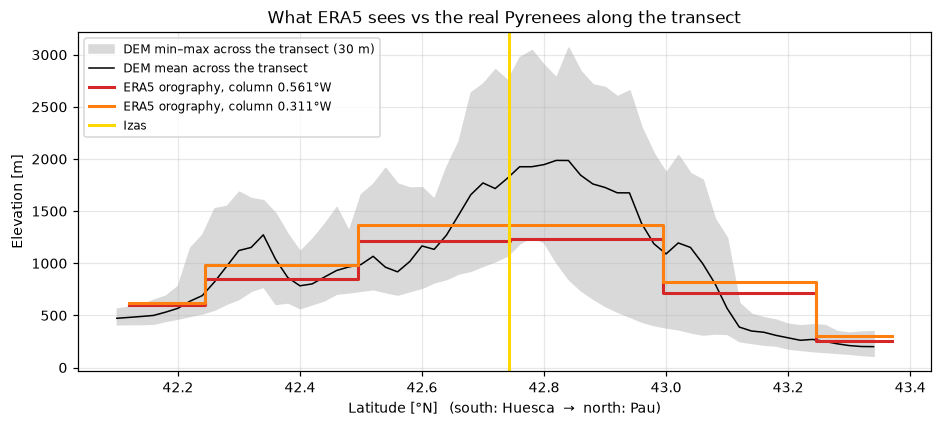

In [4]:
inside = dem.sel(x=slice(tb[0], tb[2]), y=slice(tb[3], tb[1]))
lat_rows = pu.to_ll.transform(np.full(inside.y.size, float(inside.x.mean())), inside.y.values)[1]
prof = pd.DataFrame({"min": inside.min("x").values, "mean": inside.mean("x").values,
                     "max": inside.max("x").values}, index=lat_rows)
prof = prof.groupby(np.round(prof.index / 0.02) * 0.02).agg({"min": "min", "mean": "mean", "max": "max"})
cols = pu.era5_columns(CLIM)

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(prof.index, prof["min"], prof["max"], color="0.85", label="DEM min–max across the transect (30 m)")
ax.plot(prof.index, prof["mean"], "k", lw=1, label="DEM mean across the transect")
for lo, c in zip(cols.longitude.values, ["tab:red", "tab:orange"]):
    o = cols.oro.sel(longitude=lo)
    ax.step(o.latitude, o, where="mid", color=c, lw=2, label=f"ERA5 orography, column {abs(lo):.3f}°W")
ax.axvline(pu.IZAS["lat"], color="gold", lw=2, label="Izas")
ax.set(xlabel="Latitude [°N]   (south: Huesca  →  north: Pau)", ylabel="Elevation [m]",
       title="What ERA5 sees vs the real Pyrenees along the transect")
ax.legend(fontsize=8, loc="upper left")
plt.show()

## 4. Loading the results

The outputs of notebook 1 are read from disk (`pu.load_results()`, like `Topoclass.load_project()` but faster for
thousands of files): the transect clusters with their downscaled time series, and the Izas points.

In [5]:
mp = tc.Topoclass(str(PROJ_T / "config.yml"))
down = pu.load_results(mp)                                 # = mp.load_project() + load, faster for many files
ds_param, cent = mp.toposub.ds_param, pu.centroid_table(mp)
mp_i = tc.Topoclass(str(PROJ_I / "config.yml"))
dsi = pu.load_results(mp_i)
pt_info = pu.izas_point_info(mp_i)                         # DEM parameters + group of each Izas point
z_izas = float(pt_info.loc["Izas_AWS", "elevation"])
show = partial(pu.map_clusters, params=ds_param, dem=dem)  # paint per-cluster values on their pixels
print(f"transect: {len(cent)} clusters; Izas: {len(pt_info)} points; {down.sizes['time']} time steps")


---> DEM file found
{'latN': 43.43197801847578, 'latS': 42.01684906368076, 'lonW': -0.7666124051265623, 'lonE': -0.09737113648246874}
Project lat/lon extent:

	------------------------------
	|        North:43.4          |
	|West:-0.8          East:-0.1|
	|        South:42.0          |
	------------------------------
---> Config loaded
era5 download no longer automatically done in class decalaration - please declare <mp.get_era5()> in run.py file.



---> DEM file found
{'latN': 42.84731341279392, 'latS': 42.63800681788827, 'lonW': -0.5699885713706605, 'lonE': -0.2680965741898207}
Project lat/lon extent:

	------------------------------
	|        North:42.8          |
	|West:-0.6          East:-0.3|
	|        South:42.6          |
	------------------------------
---> Config loaded
era5 download no longer automatically done in class decalaration - please declare <mp.get_era5()> in run.py file.


transect: 3000 clusters; Izas: 17 points; 2924 time steps


### Station data and the raw-ERA5 reference

* **Observations** are matched to the model time stamps: SW is averaged over the hour *ending* at each time stamp
  (exactly what the ERA5 accumulation represents); T, RH, pressure and wind are averaged over ±10 min.
* **Raw ERA5** is taken from the **nearest grid cell** to Izas (no interpolation), at its model elevation.
* TopoPyScale's SW is on the inclined surface of the DEM pixel (here 6°, NE-facing), while the pyranometer is
  levelled: for the comparison we use the **horizontal-equivalent** SW (`SW_horiz`, same diffuse, sky view and
  shading, direct beam on a horizontal plane).

In [6]:
obs10 = pu.load_izas(paths["izas_xlsx"], cache=DATA_ROOT / "raw" / "izas_10min.pkl")
mtimes = dsi.time.to_index()
obs = pu.izas_at(obs10, mtimes)
era = pu.era5_nearest(CLIM, pu.IZAS["lat"], pu.IZAS["lon"])
tps = pu.downscaled_df(dsi.sel(point_name="Izas_AWS"), mp_i.ds_solar.sel(point_name="Izas_AWS"))
pid_izas = str(ds_param.point_name.sel(x=x_izas, y=y_izas, method="nearest").item())
tps_cl = pu.downscaled_df(down.sel(point_name=pid_izas), mp.ds_solar.sel(point_name=pid_izas))
print(f"Nearest ERA5 cell: {era.attrs['lat']:.2f}N {era.attrs['lon']:.3f}E, orography {era.attrs['oro']:.0f} m "
      f"({z_izas - era.attrs['oro']:.0f} m below the station)")
print(f"Transect cluster containing Izas: {pid_izas} (centroid elevation {cent.loc[pid_izas, 'elevation']:.0f} m)")

Nearest ERA5 cell: 42.62N -0.311E, orography 1372 m (701 m below the station)
Transect cluster containing Izas: 0593 (centroid elevation 2109 m)


## 5. The long-distance North–South gradient

All analyses below use the **per-cluster time series**. Maps are made by painting each cluster's value onto its
pixels on the fly; latitudinal profiles use the number of pixels of each cluster in each latitude band, so no
gridded output is ever stored.

The maps and profiles of this section are **time averages over the two years 2019–2020, not single time steps**:

* **temperature**: mean of all 6-hourly values (4 per day);
* **precipitation**: mean annual total, from the 1-hour rates × 6 h (a sampled estimate);
* **shortwave**: mean of the daily **12 UTC** values (hour 11–12 UTC, ≈ solar noon).

In [7]:
tt = down.time.to_index()
DJF, JJA = tt.month.isin([12, 1, 2]), tt.month.isin([6, 7, 8])
H12 = tt.hour == 12
nyears = 2.0


def tmean(da, sel=None):
    return (da if sel is None else da.isel(time=np.where(sel)[0])).mean("time").to_series()


clus = pd.DataFrame({
    "T": tmean(down.t) - 273.15, "T_DJF": tmean(down.t, DJF) - 273.15, "T_JJA": tmean(down.t, JJA) - 273.15,
    "P": down.tp.sum("time").to_series() / nyears,
    "P_nolapse": (down.tp / down.precip_lapse_rate).sum("time").to_series() / nyears,
    "SW12": tmean(down.SW, H12), "SW12_DJF": tmean(down.SW, H12 & DJF), "SW12_JJA": tmean(down.SW, H12 & JJA),
}).join(cent[["elevation", "slope_deg", "aspect_deg", "northness", "svf", "lat", "lon"]])

# ERA5 along the two transect columns, same statistics
ct = cols.time.to_index()
era_cols = xr.Dataset({
    "T": cols.t2m.mean("time") - 273.15, "T_DJF": cols.t2m.isel(time=np.where(ct.month.isin([12, 1, 2]))[0]).mean("time") - 273.15,
    "T_JJA": cols.t2m.isel(time=np.where(ct.month.isin([6, 7, 8]))[0]).mean("time") - 273.15,
    "P": (cols.tp * 1000 * 6).sum("time") / nyears,
    "SW12": (cols.ssrd / 3600).isel(time=np.where(ct.hour == 12)[0]).mean("time"), "oro": cols.oro})
era_df = era_cols.to_dataframe().reset_index()

The history saving thread hit an unexpected error (OperationalError('disk I/O error')).History will not be written to the database.


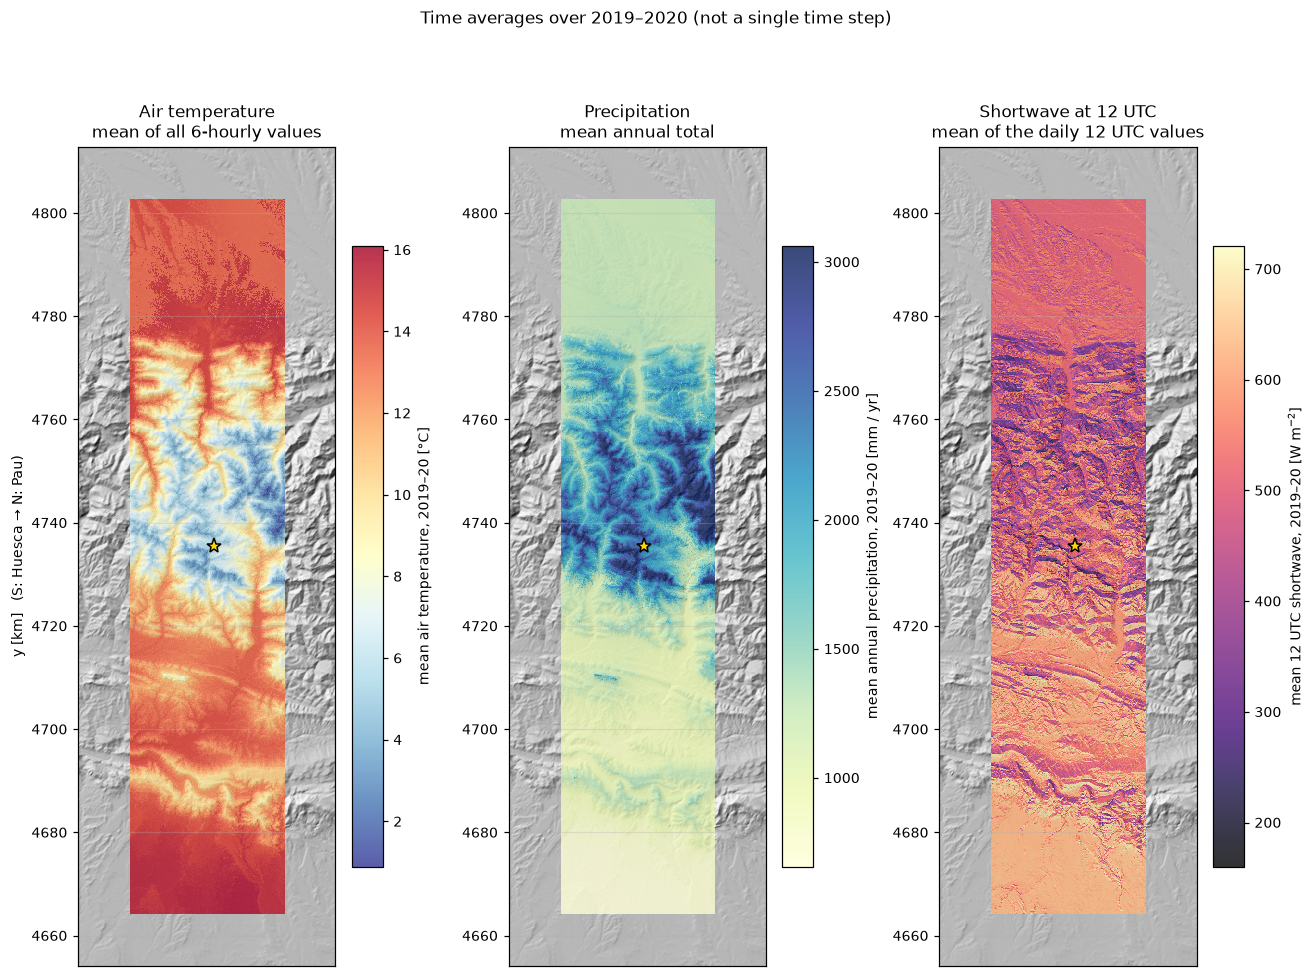

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(12, 10))
show(axs[0], clus["T"], "RdYlBu_r", "mean air temperature, 2019–20 [°C]")
show(axs[1], clus["P"], "YlGnBu", "mean annual precipitation, 2019–20 [mm / yr]", vmax=np.nanpercentile(clus.P, 98))
show(axs[2], clus["SW12"], "magma", "mean 12 UTC shortwave, 2019–20 [W m$^{-2}$]")
for a, t in zip(axs, ["Air temperature\nmean of all 6-hourly values", "Precipitation\nmean annual total",
                      "Shortwave at 12 UTC\nmean of the daily 12 UTC values"]):
    a.set_title(t)
axs[0].set_ylabel("y [km]   (S: Huesca → N: Pau)")
fig.suptitle("Time averages over 2019–2020 (not a single time step)", fontsize=11)
plt.tight_layout()
plt.show()

To separate the **climatic** N–S gradient from the **topographic** one, we compare latitudinal profiles at the
*same elevation band* (1500–2000 m) and for *flat* terrain only. The profiles show the same **2019–2020
averages** as the maps; ERA5 cell values (same averages) are shown as squares and diamonds.

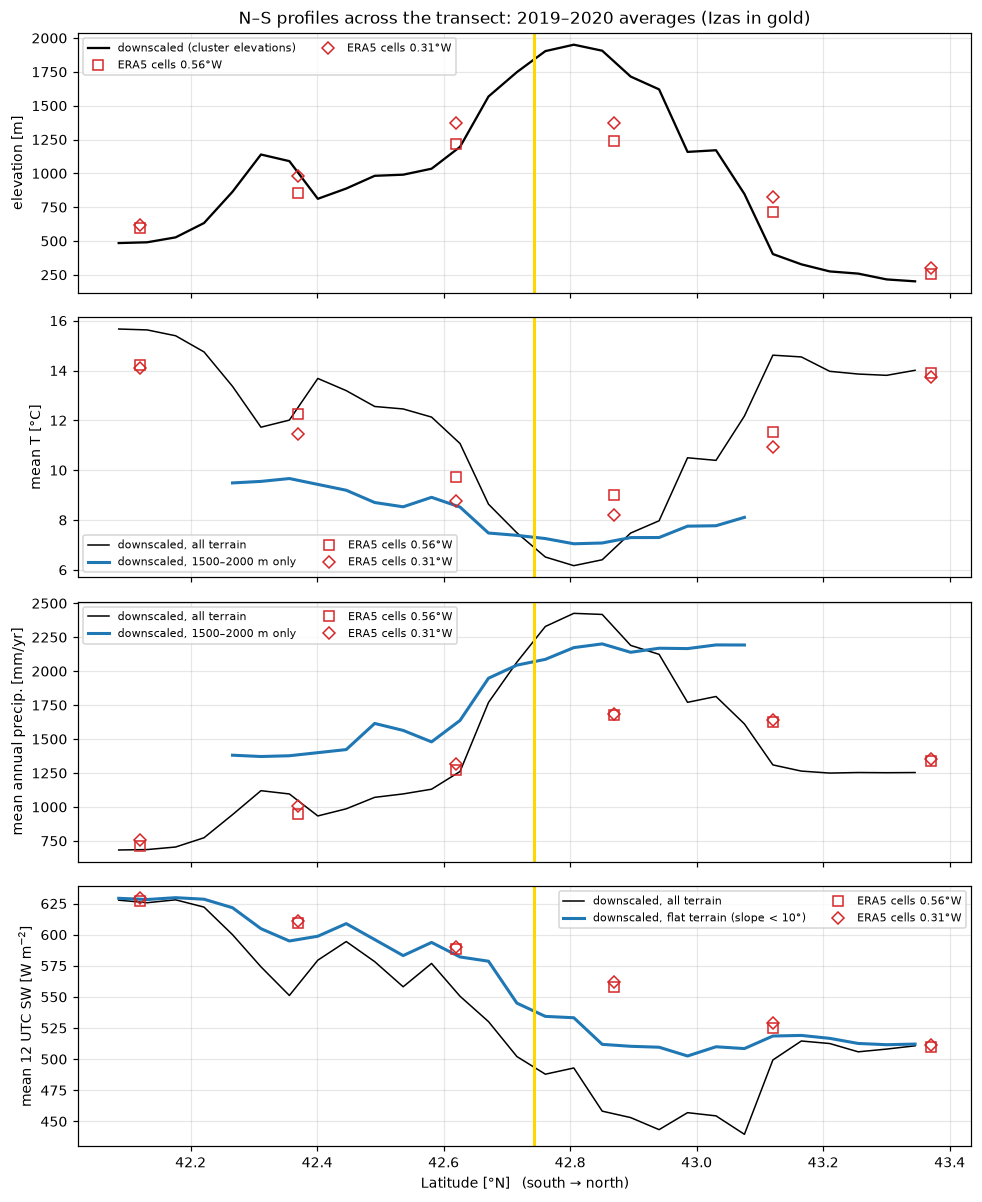

In [9]:
elev_px = ds_param.elevation.values
slope_px = np.rad2deg(ds_param.slope.values)
W_all = pu.lat_weights(ds_param, bin_km=5)
W_band = pu.lat_weights(ds_param, bin_km=5, by=(elev_px > 1500) & (elev_px < 2000))
W_flat = pu.lat_weights(ds_param, bin_km=5, by=slope_px < 10)

fig, axs = plt.subplots(4, 1, figsize=(9, 11), sharex=True)
axs[0].plot(W_all.index, pu.profile(W_all, clus.elevation), "k", label="downscaled (cluster elevations)")
axs[0].set_ylabel("elevation [m]")
for var, ax, lab in (("T", axs[1], "mean T [°C]"), ("P", axs[2], "mean annual precip. [mm/yr]"),
                     ("SW12", axs[3], "mean 12 UTC SW [W m$^{-2}$]")):
    ax.plot(W_all.index, pu.profile(W_all, clus[var]), "k", lw=1, label="downscaled, all terrain")
    if var != "SW12":
        b = pu.profile(W_band, clus[var])
        ax.plot(b.index, b, "tab:blue", lw=2, label="downscaled, 1500–2000 m only")
    else:
        f = pu.profile(W_flat, clus[var])
        ax.plot(f.index, f, "tab:blue", lw=2, label="downscaled, flat terrain (slope < 10°)")
    ax.set_ylabel(lab)
for ax, var in zip(axs, ["oro", "T", "P", "SW12"]):
    for lo, mk in zip(cols.longitude.values, ["s", "D"]):
        e_ = era_df[era_df.longitude == lo]
        ax.plot(e_.latitude, e_[var], mk, color="tab:red", mfc="none", label=f"ERA5 cells {abs(lo):.2f}°W")
    ax.axvline(pu.IZAS["lat"], color="gold", lw=2)
    ax.legend(fontsize=7, ncol=2)
axs[-1].set_xlabel("Latitude [°N]   (south → north)")
axs[0].set_title("N–S profiles across the transect: 2019–2020 averages (Izas in gold)")
plt.tight_layout()
plt.show()

**Reading the profiles.** At the *same elevation* the downscaled temperature still carries the large-scale
gradient of ERA5, while the all-terrain curve follows the topography. Precipitation is highest on the Atlantic
(northern) side. Flat-terrain shortwave shows the cloudiness contrast: more sun on the southern side.

## 6. The elevation gradient

### 6a. Along the transect

Each dot is a cluster. ERA5 cells (red squares) only span a few hundred metres of elevation and therefore
cannot represent the temperature contrast between valley floors and summits.

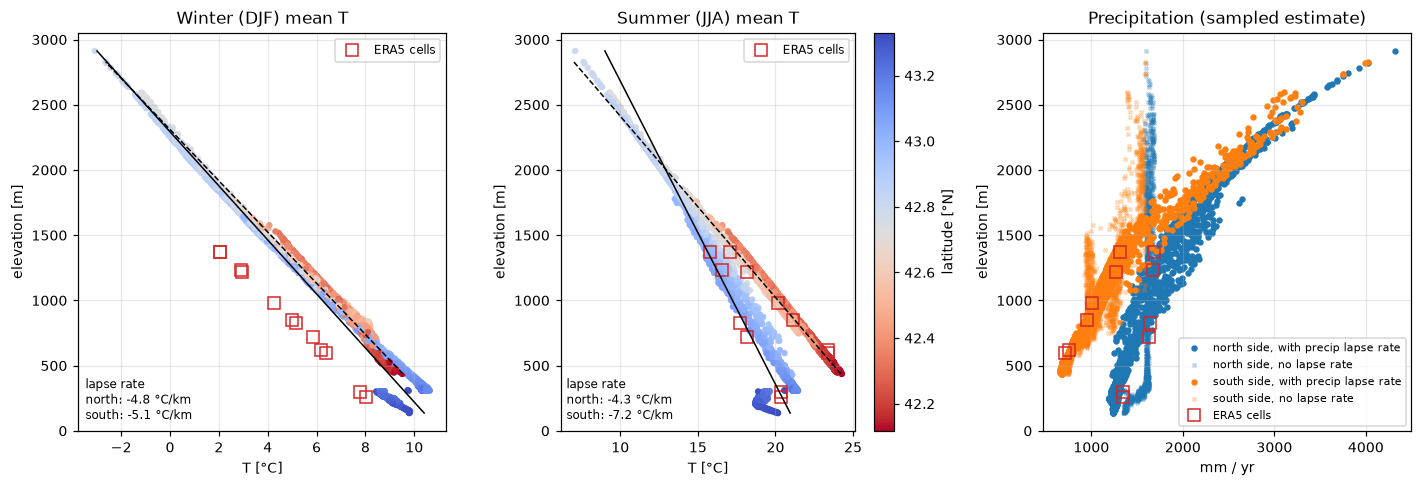

In [10]:
DIVIDE_LAT = 42.80                                   # approximate main divide along the transect
clus["side"] = np.where(clus.lat > DIVIDE_LAT, "north", "south")
fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, var, title in ((axs[0], "T_DJF", "Winter (DJF) mean T"), (axs[1], "T_JJA", "Summer (JJA) mean T")):
    sc = ax.scatter(clus[var], clus.elevation, c=clus.lat, cmap="coolwarm_r", s=10)
    ax.plot(era_df[var], era_df.oro, "s", color="tab:red", mfc="none", ms=8, label="ERA5 cells")
    txt = []
    for side, ls in (("north", "-"), ("south", "--")):
        c = clus[clus.side == side]
        a, b = np.polyfit(c.elevation / 1000, c[var], 1)
        zz = np.linspace(c.elevation.min(), c.elevation.max(), 10)
        ax.plot(a * zz / 1000 + b, zz, "k", ls=ls, lw=1)
        txt.append(f"{side}: {a:.1f} °C/km")
    ax.set(title=title, xlabel="T [°C]", ylabel="elevation [m]")
    ax.text(0.02, 0.02, "lapse rate\n" + "\n".join(txt), transform=ax.transAxes, fontsize=8, va="bottom")
    ax.legend(loc="upper right", fontsize=8)
plt.colorbar(sc, ax=axs[1], label="latitude [°N]")
for side, c in (("north", "tab:blue"), ("south", "tab:orange")):
    s_ = clus[clus.side == side]
    axs[2].scatter(s_.P, s_.elevation, s=10, color=c, label=f"{side} side, with precip lapse rate")
    axs[2].scatter(s_.P_nolapse, s_.elevation, s=6, color=c, alpha=0.3, marker="x", label=f"{side} side, no lapse rate")
axs[2].plot(era_df.P, era_df.oro, "s", color="tab:red", mfc="none", ms=8, label="ERA5 cells")
axs[2].set(title="Precipitation (sampled estimate)", xlabel="mm / yr", ylabel="elevation [m]")
axs[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

### 6b. At Izas: does the downscaled profile hit the station?

The elevation series around Izas spans ~1200–2800 m within a few km, i.e. **inside one ERA5 cell**. The station
(gold star) measures one point of that profile; raw ERA5 (red square) sits at the model's 1372 m surface.
Means are computed over the time steps where observations are available.

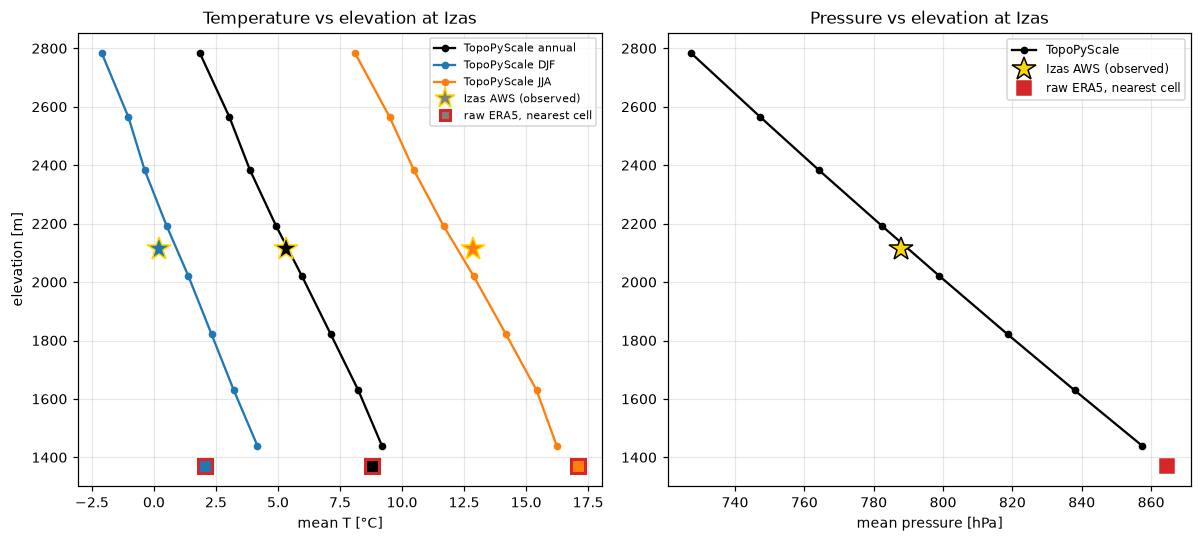

raw ERA5    : T bias +3.45 °C,  P bias +76.8 hPa
TopoPyScale : T bias +0.36 °C,  P bias +6.0 hPa
Station elevation implied by the observed pressure on the downscaled profile: 2135 m (station 2113 m, DEM pixel 2073 m)


In [11]:
ok = obs["T"].notna() & obs["P"].notna()
Z_STN = pu.IZAS["elev"]                         # observations plotted at the station elevation
es = pt_info[pt_info.group == "elevation_series"].sort_values("elevation")
seas = {"annual": np.ones(len(mtimes), bool), "DJF": mtimes.month.isin([12, 1, 2]), "JJA": mtimes.month.isin([6, 7, 8])}
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for (sname, sm), c in zip(seas.items(), ["k", "tab:blue", "tab:orange"]):
    m = sm & ok.to_numpy()
    tz = [float(dsi.t.sel(point_name=n).isel(time=np.where(m)[0]).mean()) - 273.15 for n in es.index]
    axs[0].plot(tz, es.elevation, "-o", color=c, ms=4, label=f"TopoPyScale {sname}")
    axs[0].plot(obs["T"][m].mean(), Z_STN, "*", color=c, mec="gold", ms=16)
    axs[0].plot(era["T"][m].mean(), era.attrs["oro"], "s", color=c, mec="tab:red", mew=2, ms=9)
axs[0].plot([], [], "*", color="0.5", mec="gold", ms=14, label="Izas AWS (observed)")
axs[0].plot([], [], "s", color="0.5", mec="tab:red", mew=2, label="raw ERA5, nearest cell")
axs[0].set(xlabel="mean T [°C]", ylabel="elevation [m]", title="Temperature vs elevation at Izas")
axs[0].legend(fontsize=7)
pz = [float(dsi.p.sel(point_name=n).isel(time=np.where(ok)[0]).mean()) / 100 for n in es.index]
axs[1].plot(pz, es.elevation, "-o", color="k", ms=4, label="TopoPyScale")
axs[1].plot(obs["P"][ok].mean(), Z_STN, "*", color="gold", mec="k", ms=16, label="Izas AWS (observed)")
axs[1].plot(era["P"][ok].mean(), era.attrs["oro"], "s", color="tab:red", ms=9, label="raw ERA5, nearest cell")
axs[1].set(xlabel="mean pressure [hPa]", title="Pressure vs elevation at Izas")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
for name, d in (("raw ERA5", era), ("TopoPyScale", tps)):
    print(f"{name:12s}: T bias {d['T'][ok].mean() - obs['T'][ok].mean():+.2f} °C,  "
          f"P bias {d['P'][ok].mean() - obs['P'][ok].mean():+.1f} hPa")
z_from_p = np.interp(obs["P"][ok].mean(), np.array(pz)[::-1], es.elevation.values[::-1])
print(f"Station elevation implied by the observed pressure on the downscaled profile: {z_from_p:.0f} m "
      f"(station {pu.IZAS['elev']:.0f} m, DEM pixel {z_izas:.0f} m)")

## 7. Terrain and shortwave radiation

### 7a. Along the transect

A clear winter day at noon: ERA5 has one value per ~31 km cell, TopoPyScale resolves sunny south faces, shaded
north faces and cast shadows.

Clearest Dec/Jan noon: 2019-01-24 12:00:00


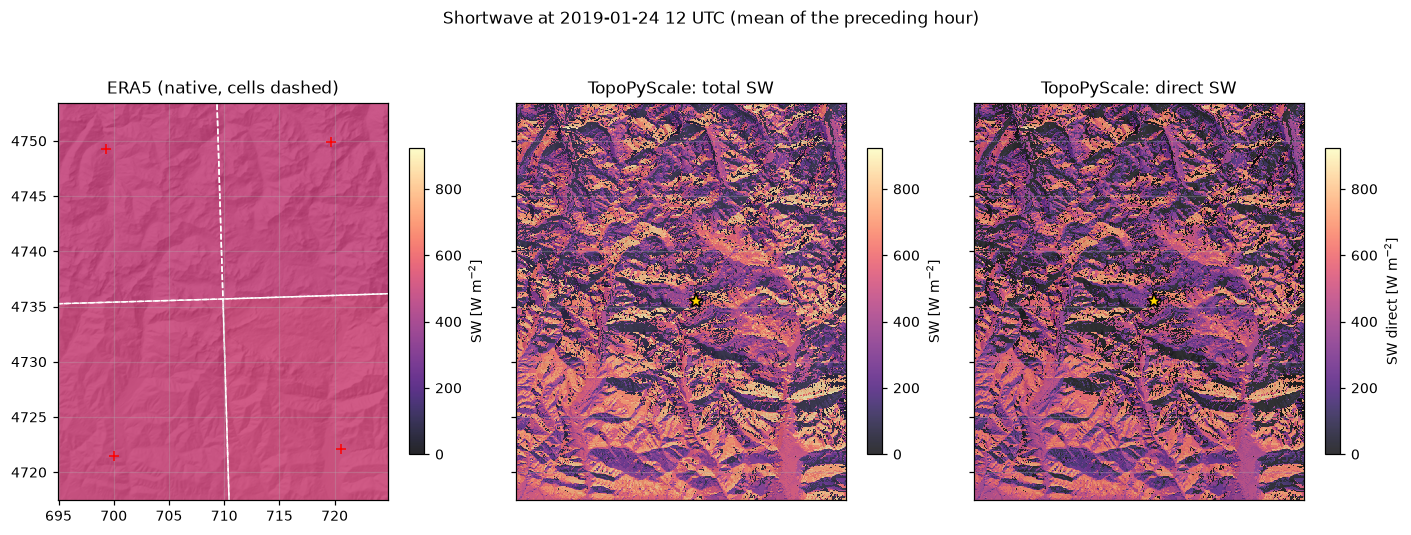

In [12]:
zoom = (tb[0], y_izas - 18e3, tb[2], y_izas + 18e3)          # 36 km around Izas, full transect width
dj12 = np.where((ct.hour == 12) & ct.month.isin([12, 1]))[0]
t_clear = ct[dj12][int((cols.ssrd.isel(time=dj12)).mean(["latitude", "longitude"]).argmax())]
print("Clearest Dec/Jan noon:", t_clear)
zoom_params = ds_param.sel(x=slice(zoom[0], zoom[2]), y=slice(zoom[3], zoom[1]))
st = 2
gx, gy = zoom_params.x.values[::st], zoom_params.y.values[::st]
era_sw = pu.era5_display_map((pu.open_era5_surf(CLIM).ssrd.sel(time=t_clear) / 3600).load(), gx, gy)
snap = down.sel(time=t_clear)
fig, axs = plt.subplots(1, 3, figsize=(13, 5.2), sharey=True)
e = [km(gx[0]), km(gx[-1]), km(gy[-1]), km(gy[0])]
vmax = float(snap.SW.max())
axs[0].imshow(pu.hillshade(dem.sel(x=gx, y=gy, method="nearest").values, DEM_RES * st), cmap="gray", extent=e)
im = axs[0].imshow(era_sw, cmap="magma", vmin=0, vmax=vmax, alpha=0.85, extent=e)
pu.draw_era5_cells(axs[0], pu.era5_cells_in(oro, (zoom[0] - 15e3, zoom[1] - 15e3, zoom[2] + 15e3, zoom[3] + 15e3)), ec="w", lw=1, ls="--")
axs[0].set(xlim=e[:2], ylim=e[2:], title="ERA5 (native, cells dashed)")
show(axs[1], snap.SW.to_series(), "magma", "SW [W m$^{-2}$]", 0, vmax, stride=st, params=zoom_params)
axs[1].set_title("TopoPyScale: total SW")
show(axs[2], snap.SW_direct.to_series(), "magma", "SW direct [W m$^{-2}$]", 0, vmax, stride=st, params=zoom_params)
axs[2].set_title("TopoPyScale: direct SW")
plt.colorbar(im, ax=axs[0], shrink=0.6, label="SW [W m$^{-2}$]")
fig.suptitle(f"Shortwave at {t_clear:%Y-%m-%d %H} UTC (mean of the preceding hour)")
plt.tight_layout()
plt.show()

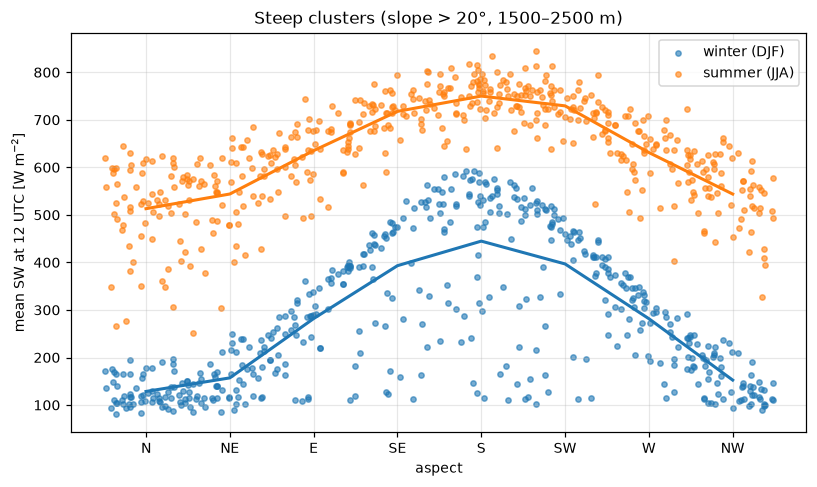

Winter noon SW, steep south-facing vs north-facing clusters: 429 vs 129 W m-2


In [13]:
steep = clus[(clus.slope_deg > 20) & clus.elevation.between(1500, 2500)]
bins = np.arange(-22.5, 360, 45)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
axs = [ax]
for var, c, lab in (("SW12_DJF", "tab:blue", "winter (DJF)"), ("SW12_JJA", "tab:orange", "summer (JJA)")):
    a = np.mod(steep.aspect_deg + 22.5, 360) - 22.5
    axs[0].scatter(a, steep[var], s=12, color=c, alpha=0.6, label=lab)
    binned = steep[var].groupby(pd.cut(a, bins)).mean()
    axs[0].plot(bins[:-1] + 22.5, binned.values, "-", color=c, lw=2)
axs[0].set(xticks=range(0, 360, 45), xticklabels=list(pu.DIRECTIONS), xlabel="aspect",
           ylabel="mean SW at 12 UTC [W m$^{-2}$]", title="Steep clusters (slope > 20°, 1500–2500 m)")
axs[0].legend()
plt.tight_layout()
plt.show()

south = steep[(steep.aspect_deg > 135) & (steep.aspect_deg < 225)].SW12_DJF.mean()
north = steep[(steep.aspect_deg < 45) | (steep.aspect_deg > 315)].SW12_DJF.mean()
print(f"Winter noon SW, steep south-facing vs north-facing clusters: {south:.0f} vs {north:.0f} W m-2")
assert south > north + 50, "south-facing slopes should receive much more winter noon SW"

### 7b. At Izas: the aspect rose next to the station

The Izas pyranometer is **horizontal**, so it measures what TopoPyScale computes for the station point (including
horizon shading). The 8 rose slopes at the same elevation show how much the aspect changes the radiation,
relative to that measured reference.

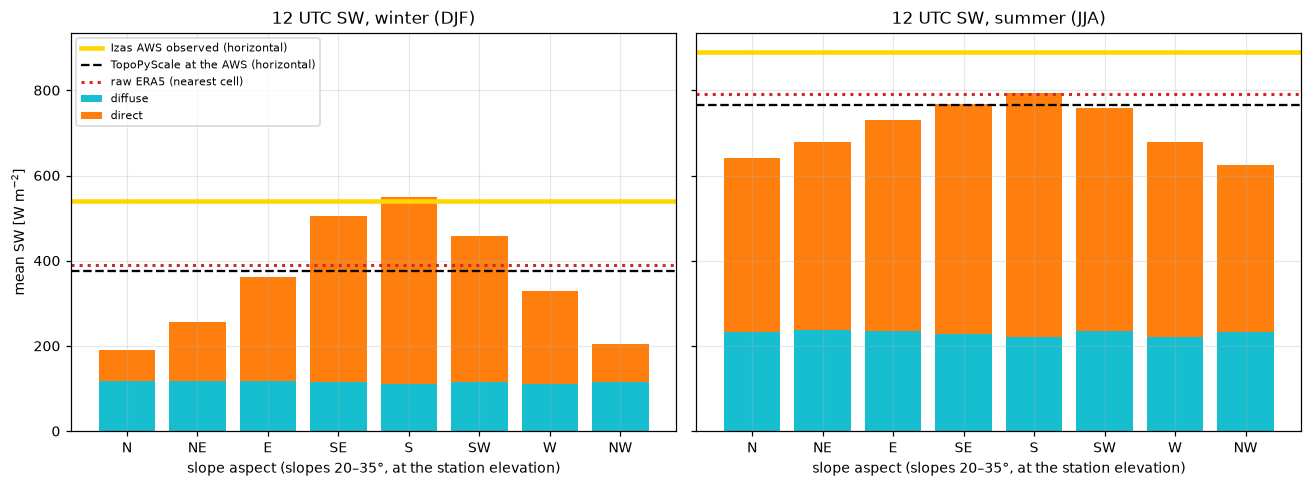

In [14]:
rose = pt_info[pt_info.group == "aspect_rose"].sort_values("target")
m12 = mtimes.hour == 12
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (sname, sm) in zip(axs, (("winter (DJF)", mtimes.month.isin([12, 1, 2])), ("summer (JJA)", mtimes.month.isin([6, 7, 8])))):
    m = m12 & sm & obs["SW"].notna().to_numpy()
    idx = np.where(m)[0]
    dir_ = [float(dsi.SW_direct.sel(point_name=n).isel(time=idx).mean()) for n in rose.index]
    dif_ = [float(dsi.SW_diffuse.sel(point_name=n).isel(time=idx).mean()) for n in rose.index]
    xs = np.arange(len(rose))
    ax.bar(xs, dif_, color="tab:cyan", label="diffuse")
    ax.bar(xs, dir_, bottom=dif_, color="tab:orange", label="direct")
    ax.axhline(obs["SW"][m].mean(), color="gold", lw=3, label="Izas AWS observed (horizontal)")
    ax.axhline(tps["SW_horiz"][m].mean(), color="k", ls="--", label="TopoPyScale at the AWS (horizontal)")
    ax.axhline(era["SW"][m].mean(), color="tab:red", ls=":", lw=2, label="raw ERA5 (nearest cell)")
    ax.set(xticks=xs, xticklabels=[n.split("_")[-1] for n in rose.index], title=f"12 UTC SW, {sname}",
           xlabel="slope aspect (slopes 20–35°, at the station elevation)")
axs[0].set_ylabel("mean SW [W m$^{-2}$]")
axs[0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

## 8. Validation at the Izas AWS

### Station vs raw ERA5 vs TopoPyScale

Three model estimates at the station: **raw ERA5** (nearest cell, at 1372 m), **TopoPyScale points mode** at the
AWS, and the **transect cluster** that contains the AWS (TopoSUB). Shortwave is compared at the **12 UTC**
samples (hour 11–12 UTC, around solar noon), with the TopoPyScale horizontal-equivalent SW.
The horizon of the station and the sun path are shown in notebook 1 (4. Horizons).

In [15]:
hours = mtimes.hour
day = np.asarray(hours == 12)                    # SW validation at the 12 UTC samples
rows = {}
for var, lab in (("T", "T [°C]"), ("RH", "RH [%]"), ("P", "pressure [hPa]"), ("WS", "wind speed [m/s]")):
    for name, d in (("raw ERA5", era), ("TopoPyScale point", tps), ("TopoPyScale cluster", tps_cl)):
        if var in d:
            rows[(lab, name)] = pu.metrics(obs[var], d[var])
for name, d, v in (("raw ERA5", era, "SW"), ("TopoPyScale point", tps, "SW_horiz"),
                   ("TopoPyScale cluster", tps_cl, "SW_horiz")):
    rows[("SW 12 UTC [W m-2]", name)] = pu.metrics(obs["SW"][day], d[v][day])
met = pd.DataFrame(rows).T
met.round(2)

bias    RMSE     r       n
T [°C]            raw ERA5               3.45    4.85  0.90  2923.0
                  TopoPyScale point      0.36    1.85  0.96  2923.0
                  TopoPyScale cluster    0.01    1.94  0.96  2923.0
RH [%]            raw ERA5               7.05   22.05  0.53  2923.0
                  TopoPyScale point     -2.87   12.75  0.86  2923.0
                  TopoPyScale cluster   -2.77   13.52  0.85  2923.0
pressure [hPa]    raw ERA5              76.82   76.84  0.98  2923.0
                  TopoPyScale point      6.00    6.04  1.00  2923.0
                  TopoPyScale cluster    2.57    2.65  1.00  2923.0
wind speed [m/s]  TopoPyScale point      2.72    4.29  0.53  2923.0
                  TopoPyScale cluster    3.19    4.75  0.53  2923.0
SW 12 UTC [W m-2] raw ERA5            -124.92  281.55  0.74   731.0
                  TopoPyScale point   -144.08  291.31  0.73   731.0
                  TopoPyScale cluster -161.38  303.27  0.72   731.0

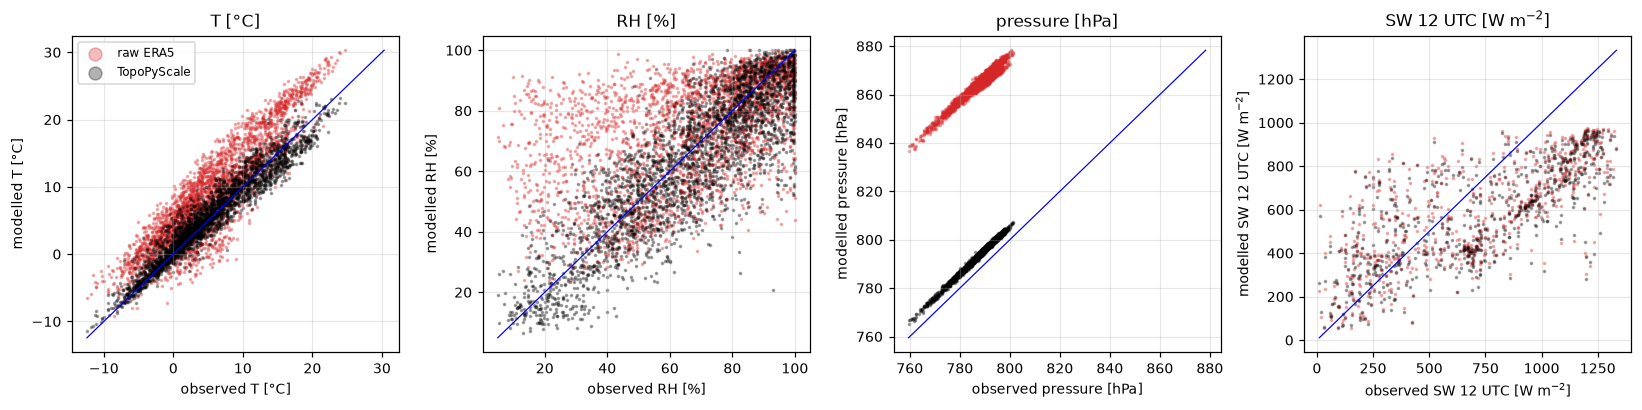

In [16]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, var, lab in zip(axs, ["T", "RH", "P", "SW"], ["T [°C]", "RH [%]", "pressure [hPa]", "SW 12 UTC [W m$^{-2}$]"]):
    sel = day if var == "SW" else np.ones(len(mtimes), bool)
    vt = "SW_horiz" if var == "SW" else var
    o = obs[var][sel]
    ax.scatter(o, era[var][sel], s=2, alpha=0.3, color="tab:red", label="raw ERA5")
    ax.scatter(o, tps[vt][sel], s=2, alpha=0.3, color="k", label="TopoPyScale")
    lim = [np.nanmin([o.min(), era[var][sel].min(), tps[vt][sel].min()]), np.nanmax([o.max(), era[var][sel].max(), tps[vt][sel].max()])]
    ax.plot(lim, lim, "b-", lw=0.8)
    ax.set(xlabel=f"observed {lab}", ylabel=f"modelled {lab}", title=lab)
axs[0].legend(markerscale=6, fontsize=8)
plt.tight_layout()
plt.show()

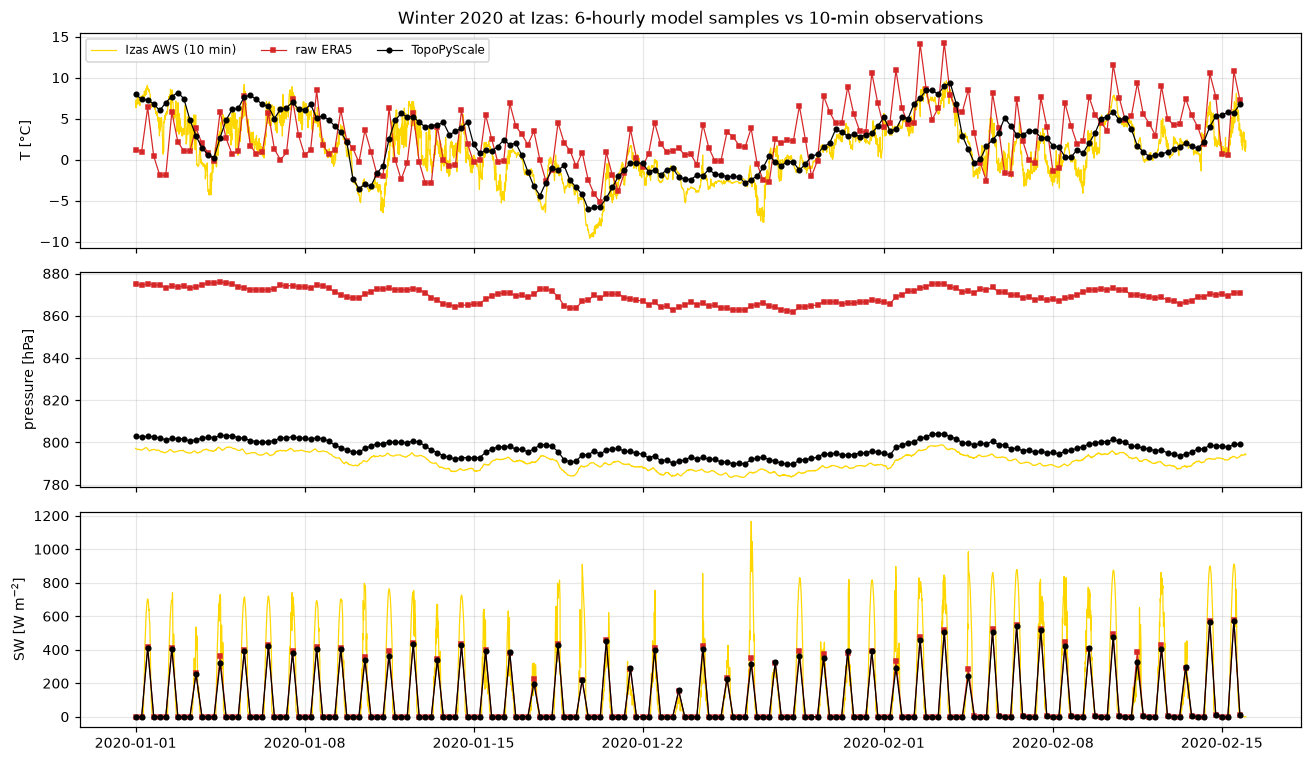

In [17]:
win_ = slice("2020-01-01", "2020-02-15")
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, var, lab in zip(axs, ["T", "P", "SW"], ["T [°C]", "pressure [hPa]", "SW [W m$^{-2}$]"]):
    ax.plot(obs10.loc[win_].index, obs10.loc[win_, var], color="gold", lw=0.8, label="Izas AWS (10 min)")
    ax.plot(era.loc[win_].index, era.loc[win_, var], "s-", color="tab:red", ms=3, lw=0.8, label="raw ERA5")
    ax.plot(tps.loc[win_].index, tps.loc[win_, "SW_horiz" if var == "SW" else var], "o-", color="k", ms=3, lw=0.8,
            label="TopoPyScale")
    ax.set_ylabel(lab)
axs[0].legend(fontsize=8, ncol=3)
axs[0].set_title("Winter 2020 at Izas: 6-hourly model samples vs 10-min observations")
plt.tight_layout()
plt.show()

### Precipitation

Monthly totals. The Geonor gauge undercatches snow at a windy site, and the models only have 4 one-hour samples per
day (scaled to 6 h), so we compare monthly totals rather than individual time steps.

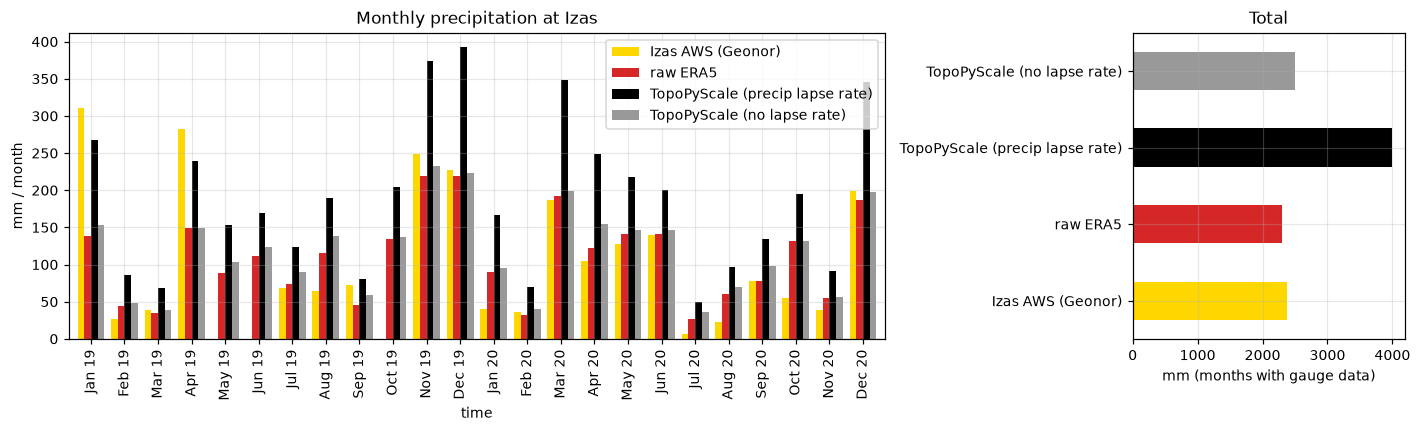

In [18]:
pr10 = pu.izas_precip(obs10)
mon = pd.DataFrame({
    "Izas AWS (Geonor)": pr10.resample("MS").sum(min_count=144 * 20),
    "raw ERA5": era["tp"].resample("MS").sum(),
    "TopoPyScale (precip lapse rate)": tps["tp"].resample("MS").sum(),
    "TopoPyScale (no lapse rate)": tps["tp_nolapse"].resample("MS").sum(),
}).loc["2019":"2020"]
fig, axs = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})
mon.plot.bar(ax=axs[0], width=0.8, color=["gold", "tab:red", "k", "0.6"])
axs[0].set_xticklabels([d.strftime("%b %y") for d in mon.index], rotation=90)
axs[0].set(ylabel="mm / month", title="Monthly precipitation at Izas")
mon.dropna().sum().plot.barh(ax=axs[1], color=["gold", "tab:red", "k", "0.6"])
axs[1].set(xlabel="mm (months with gauge data)", title="Total")
plt.tight_layout()
plt.show()

## 9. Snow: FSM driven by the downscaled forcing

TopoPyScale exports forcing for the Factorial Snow Model (FSM, Essery 2015). The exporter and the FSM namelist use
the **6-hourly time step** of the forcing (`dt = 21600 s`); outputs are daily means (`nave = 4`).
The simulation starts snow-free on 1 January 2019, which matches the station: until 20 January 2019 the SR50 shows
0–3 cm (bare-ground noise), and the first snowfall arrives on 20–21 January. We compare both seasons.

FSM (FSM): 17 points simulated, time step 21600 s, daily outputs


FSM (FSMnl): 17 points simulated, time step 21600 s, daily outputs
[FSM: Izas points] computed in 0.1 min


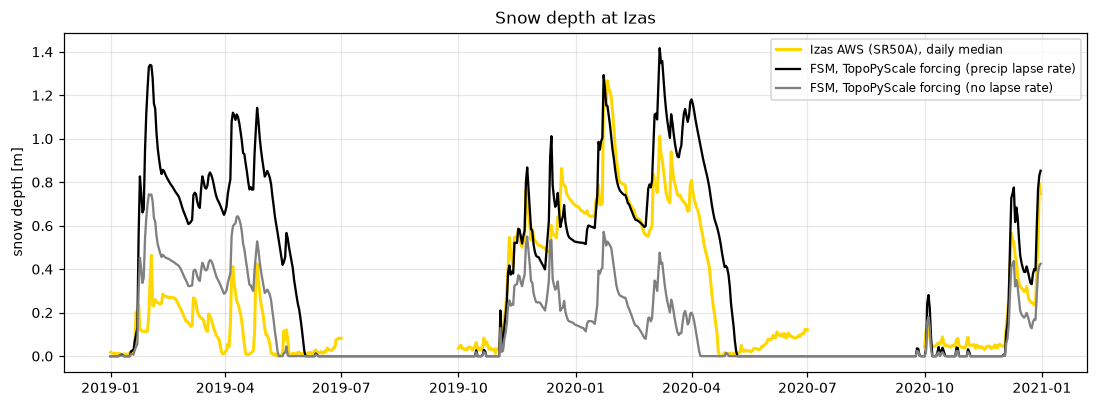

Jan–Jul 2019, FSM (lapse rate   ): {'bias': 0.44, 'RMSE': 0.55, 'r': 0.7, 'n': 182.0}, peak 1.34 m vs obs 0.46 m
Jan–Jul 2019, FSM (no lapse rate): {'bias': 0.14, 'RMSE': 0.21, 'r': 0.78, 'n': 182.0}, peak 0.74 m vs obs 0.46 m
Oct 2019–Jul 2020, FSM (lapse rate   ): {'bias': 0.06, 'RMSE': 0.2, 'r': 0.89, 'n': 275.0}, peak 1.42 m vs obs 1.27 m
Oct 2019–Jul 2020, FSM (no lapse rate): {'bias': -0.29, 'RMSE': 0.37, 'r': 0.82, 'n': 275.0}, peak 0.57 m vs obs 1.27 m


In [19]:
if RUN_FSM:
    with timed("FSM: Izas points"):
        snd_i, swe_i = pu.run_fsm(mp_i, FSM_EXEC, ds=dsi, tag="FSM", n_core=CPU_CORES)
        ds_nl = dsi.copy()
        ds_nl["tp"] = dsi.tp / dsi.precip_lapse_rate
        snd_inl, _ = pu.run_fsm(mp_i, FSM_EXEC, ds=ds_nl, tag="FSMnl", n_core=CPU_CORES)
hs_obs = pu.izas_snow_depth(obs10)
day_idx = lambda da: da.assign_coords(time=da.time.to_index().normalize())
snd_i, snd_inl = day_idx(snd_i), day_idx(snd_inl)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hs_obs.loc["2019":"2020"].index, hs_obs.loc["2019":"2020"], color="gold", lw=2, label="Izas AWS (SR50A), daily median")
ax.plot(snd_i.time, snd_i.sel(point_name="Izas_AWS"), "k", label="FSM, TopoPyScale forcing (precip lapse rate)")
ax.plot(snd_inl.time, snd_inl.sel(point_name="Izas_AWS"), color="0.5", label="FSM, TopoPyScale forcing (no lapse rate)")
ax.set(ylabel="snow depth [m]", title="Snow depth at Izas")
ax.legend(fontsize=8)
plt.show()

seasons = {"Jan–Jul 2019": slice("2019-01-01", "2019-07-31"), "Oct 2019–Jul 2020": slice("2019-10-01", "2020-07-31")}
for sname, s in seasons.items():
    hs_s = hs_obs.loc[s]
    for lab, da in (("lapse rate", snd_i), ("no lapse rate", snd_inl)):
        m = da.sel(point_name="Izas_AWS").to_series().loc[s]
        print(f"{sname}, FSM ({lab:13s}): {pu.metrics(hs_s, m).round(2).to_dict()}, "
              f"peak {m.max():.2f} m vs obs {hs_s.max():.2f} m")

### Snow along the whole transect

FSM is cheap: we run it for every cluster and map the snow-cover duration of the 2019–20 season.

FSM (FSM): 3000 points simulated, time step 21600 s, daily outputs


[FSM: 3000 clusters] computed in 2.6 min


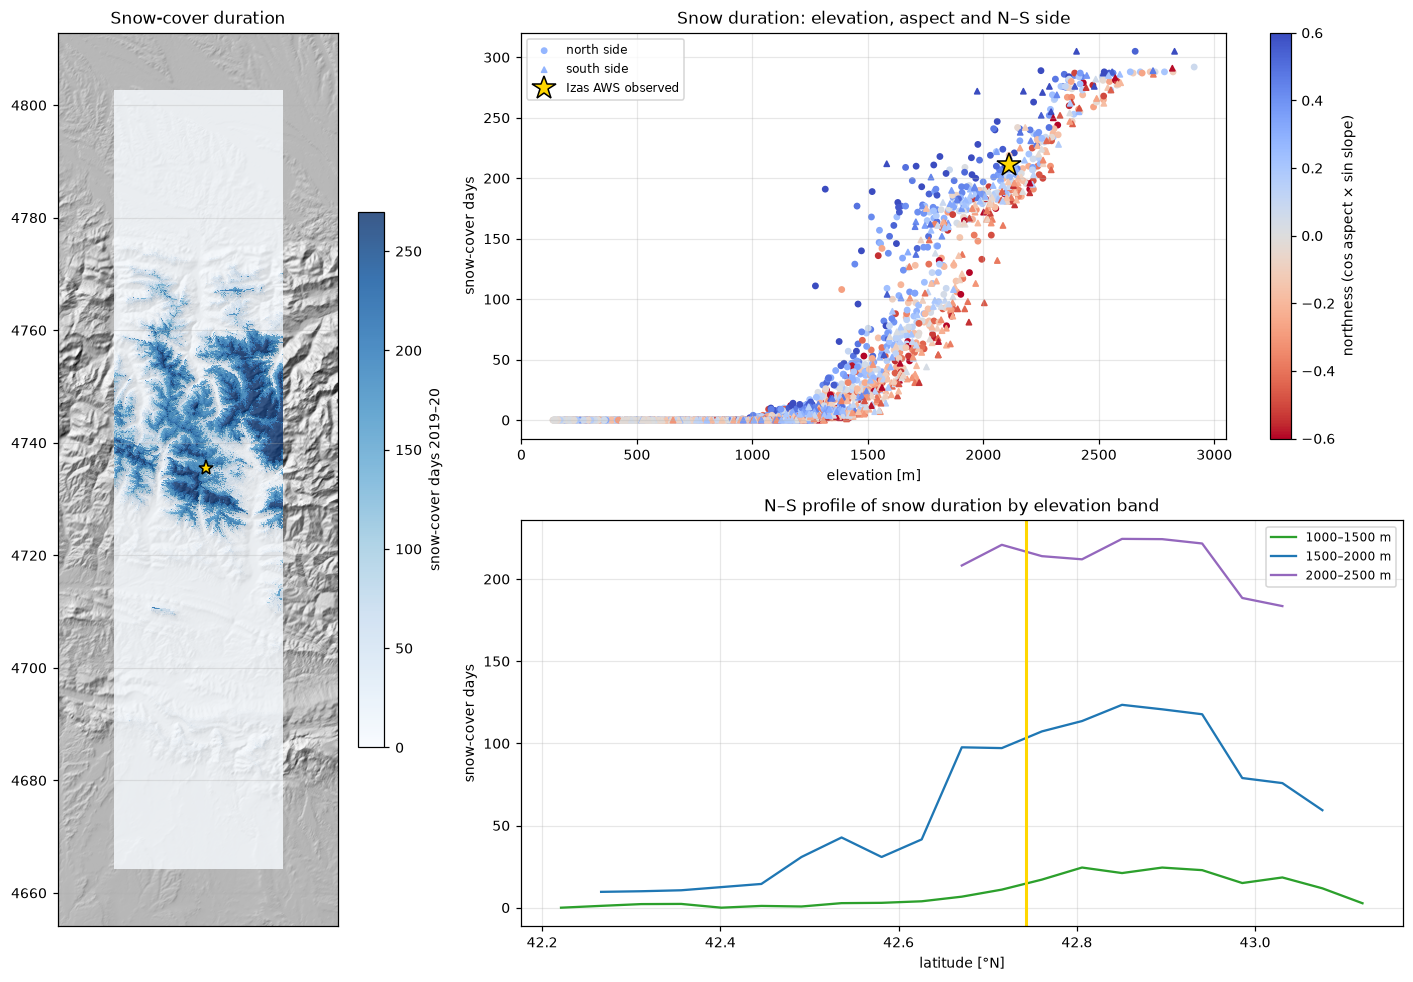

In [20]:
if RUN_FSM:
    with timed(f"FSM: {len(cent)} clusters"):
        snd_t, swe_t = pu.run_fsm(mp, FSM_EXEC, ds=down, tag="FSM", n_core=CPU_CORES)
snd_t = day_idx(snd_t)
s1920 = seasons["Oct 2019–Jul 2020"]
scd = lambda da: (da.sel(time=s1920) > 0.05).sum("time").to_series()   # snow-cover days (HS > 5 cm), 2019-20
scd_obs = int((hs_obs.loc[s1920] > 0.05).sum())
clus["SCD"] = scd(snd_t)
fig = plt.figure(figsize=(13, 9))
ax0 = fig.add_subplot(1, 3, 1)
show(ax0, clus.SCD, "Blues", "snow-cover days 2019–20", vmin=0, vmax=270)
ax0.set_title("Snow-cover duration")
ax1 = fig.add_subplot(2, 3, (2, 3))
for side, c in (("north", "tab:blue"), ("south", "tab:orange")):
    s_ = clus[clus.side == side]
    sc = ax1.scatter(s_.elevation, s_.SCD, s=12, c=s_.northness, cmap="coolwarm_r", vmin=-0.6, vmax=0.6,
                     marker="o" if side == "north" else "^", label=f"{side} side")
ax1.plot(pu.IZAS["elev"], scd_obs, "*", color="gold", mec="k", ms=16, label="Izas AWS observed")
plt.colorbar(sc, ax=ax1, label="northness (cos aspect × sin slope)")
ax1.set(xlabel="elevation [m]", ylabel="snow-cover days", title="Snow duration: elevation, aspect and N–S side")
ax1.legend(fontsize=8)
ax2 = fig.add_subplot(2, 3, (5, 6))
for lo_, hi_, c in ((1000, 1500, "tab:green"), (1500, 2000, "tab:blue"), (2000, 2500, "tab:purple")):
    W_ = pu.lat_weights(ds_param, bin_km=5, by=(elev_px > lo_) & (elev_px < hi_))
    p_ = pu.profile(W_, clus.SCD)
    ax2.plot(p_.index, p_, color=c, label=f"{lo_}–{hi_} m")
ax2.axvline(pu.IZAS["lat"], color="gold", lw=2)
ax2.set(xlabel="latitude [°N]", ylabel="snow-cover days", title="N–S profile of snow duration by elevation band")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
The summary of what TopoPyScale adds to ERA5 here, its limitations and the compute times are at the end of
[`1_downscaling.ipynb`](1_downscaling.ipynb).